# 05 — DPformer + MOSSA

1 model (DPformer) × 5 horizon × 2 setting = **10 run**. Data: harga emas **Antam (IDR)** + 7 indikator makro **stasioner** (`data_gabungan.csv`).

Konfigurasi mengikuti **Table 3 jurnal acuan** (Bao et al., 2026) sedekat mungkin (semua konstanta di `src/config.py`): `SEQ_LEN = 10`, AdamW, z-score fit train-saja, kanal eksogen di-clip ±5.
**DPformer** memakai (learning rate, weight decay) hasil **MOSSA** (jurnal §2.4), dicari 1× per setting pada h=20. **Fitness = MAE pada baris VALIDASI** (`eval_split='val'`, embargo h hari); baris uji tidak disentuh selama tuning.

**Anggaran MOSSA FULL**: populasi 20, producers 20%, early warners 10%, ≤100 iterasi, lr ∈ [1e-4, 1e-2], wd ∈ [0, 1e-2]. Mode QUICK hanya smoke test.

**Penghentian dini (adaptasi komputasi, dilaporkan).** `MOSSA_PATIENCE = 20` (`src/config.py`): pencarian berhenti bila `best_fit` tidak membaik ≥ 0,1% selama 20 iterasi berturut-turut; 100 iterasi tetap batas maksimum. Jumlah iterasi yang benar-benar berjalan tercatat di `mossa_dpformer.json`. **Catatan jujur:** perbaikan fitness dari tuning ini kecil (≈0,2–0,3%; lihat notebook 14), sehingga manfaat MOSSA harus dilaporkan secara hati-hati.

**Perkiraan waktu (CPU 2 thread):** MOSSA beberapa jam; 10 run akhir sekitar 20–40 menit. Hasil yang sudah ada dan valid dilewati otomatis (aman dilanjutkan kapan saja).

In [1]:
import sys, os, json, time, warnings

# Batasi thread CPU supaya laptop tetap responsif selama training berjam-jam.
# Default 2 thread. Ubah lewat env TA_THREADS. Harus di kernel BARU (sebelum numpy/tensorflow aktif).
N_THREADS = int(os.environ.get('TA_THREADS', '2'))
for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ.setdefault(_v, str(N_THREADS))

sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
try:
    tf.config.threading.set_intra_op_parallelism_threads(N_THREADS)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    print('[PERHATIAN] TensorFlow sudah aktif di kernel ini, batas thread tidak berlaku. Restart kernel.')

from src.config import (OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK,
                        SEQ_LEN, EPOCHS, PATIENCE, BASE_LR, BASE_WD, DL_BATCH, DL_UNITS)
from src import analysis as A, plots as P, stats as S, runners as R
from src.pipeline import SEED, load_mossa, free_memory
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
RUNS = os.path.join(RES, 'runs')
FIGS = os.path.join(OUT, 'figures')
MODEL_DIR = os.path.join(RES, 'models')
for _d in (RES, RUNS, FIGS, MODEL_DIR):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))


def simpan(fig, nama):
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)

from src.pipeline import multihorizon_split, EXO_COLS
from src.models_dl import BUILDERS, mossa_tune
from src.config import (MOSSA_EPOCHS, MOSSA_H, MOSSA_POP, MOSSA_ITER, LR_RANGE, WD_RANGE, MOSSA_PATIENCE,
                        MOSSA_MIN_REL_DELTA, SHAP_H)
FORCE_RERUN = False
print(f'Total run: 1 model x {len(HORIZONS)} horizon x {len(SETUPS)} setting = {len(HORIZONS) * len(SETUPS)}')

Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44
Total run: 1 model x 5 horizon x 2 setting = 10


## Arsitektur DPformer (diagram)

Diagram berikut digambar dari **implementasi di proyek ini** (`src/models_dl.py::build_dpformer`), sebagai padanan Fig. 2 jurnal acuan. Bagian yang tidak dirinci jurnal (cara menentukan θ, konfigurasi blok Dense) diisi dengan pilihan yang dicatat sebagai adaptasi di kode.

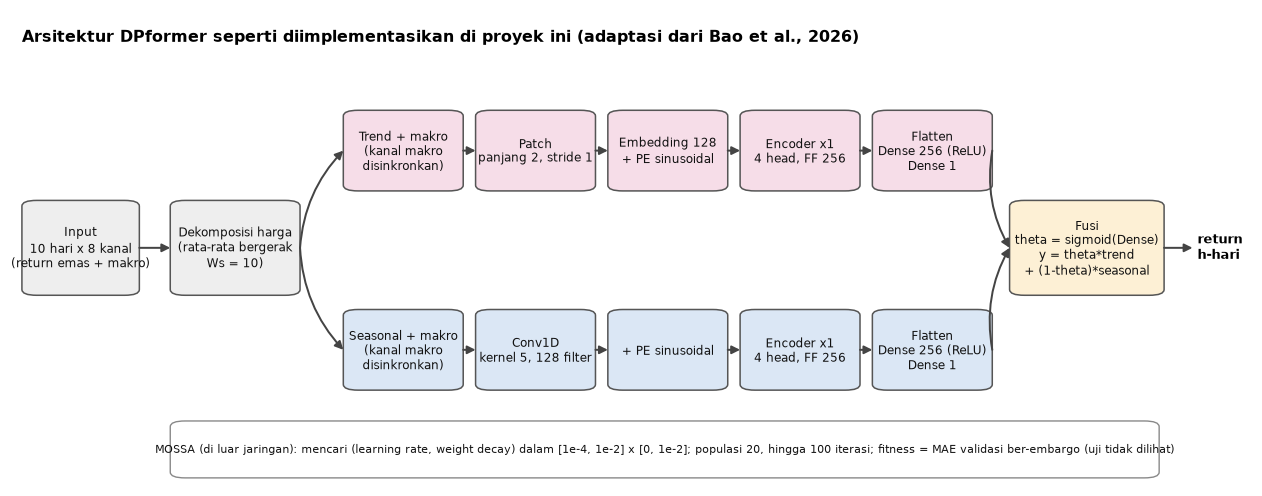

In [2]:
fig = P.fig_dpformer_arch(n_feat=1 + len(EXO_COLS), seq_len=SEQ_LEN, d_model=DL_UNITS['dpformer'])
simpan(fig, 'fig_arsitektur_dpformer')

## Uji kebocoran fitness (otomatis, ± 1 menit)

Sel berikut **merusak seluruh data dari hari pertama periode uji** (harga × 3, makro diubah) lalu melatih singkat dengan `eval_split='val'`. Bila fitness benar-benar tidak melihat data uji, MAE validasi harus **identik** dengan data asli. Kontrol positif: metrik **uji** harus berubah (bila tidak, uji ini tak berguna). Gagal = `AssertionError` dan notebook berhenti.

In [3]:
from src.checks import cek_fitness_tanpa_kebocoran

hasil_guard = cek_fitness_tanpa_kebocoran(
    p, exo, MOSSA_H, __import__('src.pipeline', fromlist=['train_dl_h']).train_dl_h,
    BUILDERS['dpformer'], SEQ_LEN, DL_UNITS['dpformer'], DL_BATCH['dpformer'])
print('[OK] fitness validasi tidak bergantung pada data uji')
for k, v in hasil_guard.items():
    print(f'  {k:28s}: {v:,.6f}')


[OK] fitness validasi tidak bergantung pada data uji
  mae_val_asli                : 18,904.916413
  mae_val_test_dirusak        : 18,904.916413
  noise_run_ulang             : 0.000000
  mae_test_asli               : 63,137.265142
  mae_test_test_dirusak       : 192,339.704010


## MOSSA: tuning (learning_rate, weight_decay) untuk DPformer

Dijalankan sekali per setting (univariat/multivariat) pada h=20, 10 epoch per evaluasi (tanpa early stopping).
Algoritmanya **SSA/MOSSA single-objective** (jurnal menyebut MOSSA multi-objective tetapi tidak memberi pseudocode maupun objective kedua; objective tidak diada-adakan). Pencarian di ruang ternormalisasi dengan `learning_rate` pada skala log.

**Checkpoint (anti-macet).** Progres disimpan ke `outputs/results/mossa_ckpt_<setting>.json` setelah populasi awal dan di akhir setiap iterasi. Bila kernel mati, jalankan ulang sel di bawah: pencarian lanjut dari iterasi terakhir. Checkpoint hanya dipakai bila konfigurasi dan versi protokol sama; `FORCE_RERUN = True` mengabaikannya. Error kehabisan memori tidak dicatat sebagai "fitness buruk".

In [4]:
from src.pipeline import train_dl_h, save_mossa

mossa_path = os.path.join(RES, 'mossa_dpformer.json')
mossa_results = None if FORCE_RERUN else load_mossa(mossa_path)    # {setup: (lr, wd, history)}

if mossa_results is not None:
    print('MOSSA DPformer: pakai hasil tersimpan (protokol sama). Hapus outputs/results/mossa_dpformer.json untuk cari ulang.')
else:
    mossa_results, mossa_full = {}, {}
    for setup in SETUPS:
        exo_use = exo if setup == 'multivariat' else None
        print(f'--- MOSSA DPformer: {setup} (h={MOSSA_H}, fitness = MAE VALIDASI) ---')
        trace = []

        def fitness(lr, wd, _exo=exo_use):
            """Fitness = MAE harga pada baris VALIDASI (eval_split='val': baris uji tidak disentuh)."""
            _, metrics, *_ = train_dl_h(
                p, _exo, MOSSA_H, BUILDERS['dpformer'], SEQ_LEN, DL_UNITS['dpformer'],
                epochs=MOSSA_EPOCHS, patience=MOSSA_EPOCHS, batch_size=DL_BATCH['dpformer'],
                learning_rate=lr, weight_decay=wd, eval_split='val')
            free_memory()
            return metrics['MAE']

        best_lr, best_wd, hist = mossa_tune(
            fitness, n_pop=MOSSA_POP, n_iter=MOSSA_ITER, lr_range=LR_RANGE, wd_range=WD_RANGE, trace=trace,
            checkpoint_path=os.path.join(RES, f'mossa_ckpt_{setup}.json'), resume=not FORCE_RERUN,
            patience_iter=MOSSA_PATIENCE, min_rel_delta=MOSSA_MIN_REL_DELTA,
            ckpt_meta={'protocol': PROTOCOL, 'fitness_split': 'val', 'setup': setup, 'h': MOSSA_H, 'epochs': MOSSA_EPOCHS})
        mossa_results[setup] = (best_lr, best_wd, hist)
        mossa_full[setup] = (best_lr, best_wd, hist, trace)
        print(f'  -> {setup}: lr={best_lr:.2e}, weight_decay={best_wd:.2e}')

    save_mossa(mossa_path, mossa_full, meta={
        'model': 'dpformer', 'h': MOSSA_H, 'epochs': MOSSA_EPOCHS, 'n_pop': MOSSA_POP, 'n_iter': MOSSA_ITER,
        'lr_range': list(LR_RANGE), 'wd_range': list(WD_RANGE),
        'fitness': 'MAE harga pada baris validasi (embargo h hari); eval_split=val',
        'patience_iter': MOSSA_PATIENCE, 'min_rel_delta': MOSSA_MIN_REL_DELTA,
        'iterasi_dijalankan': {k: len(v[2]) - 1 for k, v in mossa_full.items()}})
    print(f'Hasil MOSSA tersimpan: {mossa_path}')
    for _s in SETUPS:                       # hasil final aman -> hapus checkpoint sementara
        _ck = os.path.join(RES, f'mossa_ckpt_{_s}.json')
        if os.path.exists(_ck):
            os.remove(_ck)

--- MOSSA DPformer: univariat (h=20, fitness = MAE VALIDASI) ---
    MOSSA: lanjut dari checkpoint (iterasi 22/100 sudah selesai)
    MOSSA berhenti dini di iterasi 22/100: best_fit tidak membaik >= 0.1% selama 20 iterasi berturut-turut
  -> univariat: lr=7.18e-04, weight_decay=8.44e-03
--- MOSSA DPformer: multivariat (h=20, fitness = MAE VALIDASI) ---
    MOSSA: lanjut dari checkpoint (iterasi 26/100 sudah selesai)
    MOSSA iter 27/100: best_fit=18256.11 lr=9.27e-04 wd=7.55e-03
    MOSSA iter 28/100: best_fit=18256.11 lr=9.27e-04 wd=7.55e-03
    MOSSA berhenti dini di iterasi 28/100: best_fit tidak membaik >= 0.1% selama 20 iterasi berturut-turut
  -> multivariat: lr=9.27e-04, weight_decay=7.55e-03
Hasil MOSSA tersimpan: ..\outputs\results\mossa_dpformer.json


MAE acuan "harga tidak berubah" pada baris validasi (h=20): 19,029
  univariat  : best_fit=18,637 (0.98x acuan-val) | lr=7.18e-04 wd=8.44e-03 | OK
  multivariat: best_fit=18,256 (0.96x acuan-val) | lr=9.27e-04 wd=7.55e-03 | OK


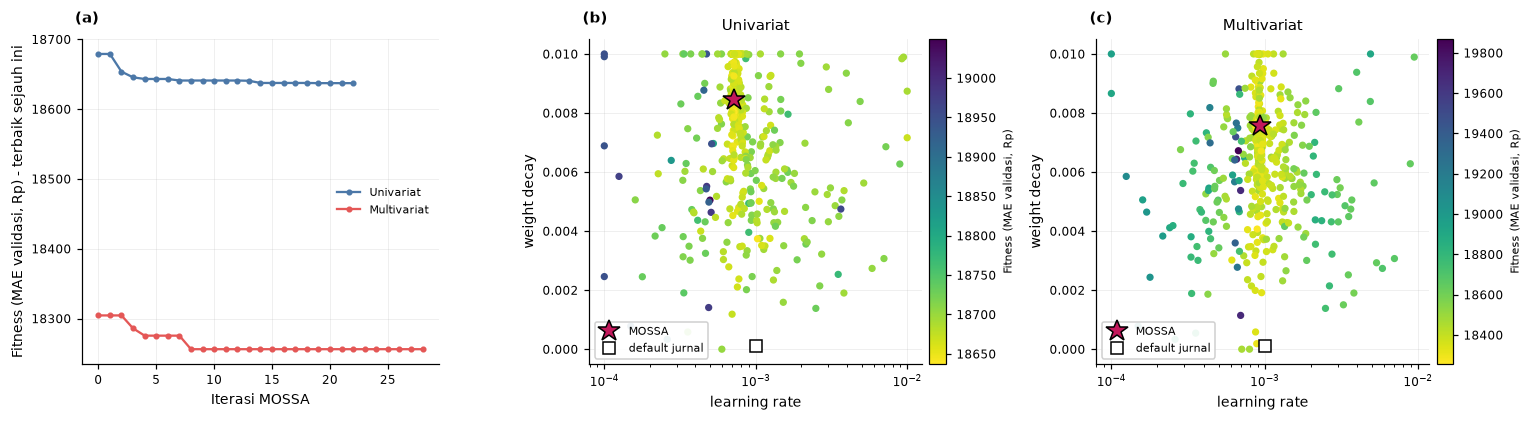

In [5]:
# Pemeriksaan hasil MOSSA (hanya membaca)
_, va_d, te_pos_chk = multihorizon_split(p, MOSSA_H)
pos_of = {d: i for i, d in enumerate(p.index)}
va_ev = [pos_of[d] for d in va_d if pos_of[d] + MOSSA_H < te_pos_chk[0]]
val_reference = float(np.mean(np.abs(p.iloc[[i + MOSSA_H for i in va_ev]].values - p.iloc[va_ev].values)))
print(f'MAE acuan "harga tidak berubah" pada baris validasi (h={MOSSA_H}): {val_reference:,.0f}')
for setup, (lr, wd, hist) in mossa_results.items():
    bf = hist[-1]['best_fit']
    pesan = []
    if not (0.3 < bf / val_reference < 3):
        pesan.append('fitness jauh dari skala acuan validasi, periksa')
    if lr <= LR_RANGE[0] * 1.07 or lr >= LR_RANGE[1] / 1.07:
        pesan.append('lr menempel di batas ruang cari')
    tol = 0.03 * (WD_RANGE[1] - WD_RANGE[0])
    if wd <= WD_RANGE[0] + tol or wd >= WD_RANGE[1] - tol:
        pesan.append('wd menempel di batas ruang cari')
    print(f'  {setup:11s}: best_fit={bf:,.0f} ({bf / val_reference:.2f}x acuan-val) | lr={lr:.2e} wd={wd:.2e}'
          + (' | PERHATIAN: ' + '; '.join(pesan) if pesan else ' | OK'))
fig = P.fig_mossa(json.load(open(mossa_path, encoding='utf-8')))
simpan(fig, 'fig_mossa_konvergensi')

## Training akhir DPformer (5 horizon × 2 setting)

100 epoch maksimum + early stopping pada validasi ber-embargo. Bobot terbaik h=20 disimpan di `outputs/results/models/` untuk SHAP (notebook 11) tanpa melatih ulang.

In [6]:
def run_fn(setup, model, h):
    lr, wd = mossa_results[setup][0], mossa_results[setup][1]
    return R.run_dl(p, exo if setup == 'multivariat' else None, setup, 'dpformer', h, lr=lr, wd=wd,
                    weights_path=os.path.join(MODEL_DIR, f'dpformer_{setup}_h{h}.weights.h5') if h == SHAP_H else None,
                    data_hash=DATA_HASH)


tasks = [(s, 'dpformer', h) for s in SETUPS for h in HORIZONS]
cnt = R.run_grid(tasks, run_fn, RUNS, data_hash=DATA_HASH, force=FORCE_RERUN)
assert cnt['gagal'] == 0, f"Ada run gagal: {cnt['daftar_gagal']}"

RUN  univariat/dpformer/h1 ... OK MAE=13,221 (72.7s, 14 epoch, terbaik=4)
RUN  univariat/dpformer/h5 ... OK MAE=30,012 (81.8s, 16 epoch, terbaik=6)
RUN  univariat/dpformer/h10 ... OK MAE=42,517 (87.1s, 17 epoch, terbaik=7)
RUN  univariat/dpformer/h20 ... OK MAE=63,154 (87.4s, 15 epoch, terbaik=5)
RUN  univariat/dpformer/h30 ... OK MAE=83,643 (207.5s, 25 epoch, terbaik=15)
RUN  multivariat/dpformer/h1 ... OK MAE=13,299 (134.0s, 14 epoch, terbaik=4)
RUN  multivariat/dpformer/h5 ... OK MAE=30,073 (93.8s, 13 epoch, terbaik=3)
RUN  multivariat/dpformer/h10 ... OK MAE=42,139 (109.4s, 20 epoch, terbaik=10)
RUN  multivariat/dpformer/h20 ... OK MAE=62,832 (90.9s, 19 epoch, terbaik=9)
RUN  multivariat/dpformer/h30 ... OK MAE=84,269 (85.8s, 17 epoch, terbaik=7)

Selesai. Baru: 10 (menimpa hasil basi: 0) | sudah ada & valid: 0 | gagal: 0


In [7]:
hasil = R.read_runs(RUNS, SETUPS, ['dpformer'], HORIZONS, data_hash=DATA_HASH)
print(f'Total hasil DPformer: {len(hasil)} / {len(HORIZONS) * len(SETUPS)}')
display(hasil[['setup', 'horizon', 'MAE', 'RMSE', 'sMAPE', 'MAPE', 'lr_used', 'wd_used', 'best_epoch', 'n_epochs']])

Total hasil DPformer: 10 / 10


,setup,horizon,MAE,RMSE,sMAPE,MAPE,lr_used,wd_used,best_epoch,n_epochs
0,univariat,1,13220.856217,21730.033581,0.690233,0.690132,0.000718,0.008442,4,14
1,univariat,5,30012.329067,46733.067213,1.566612,1.560374,0.000718,0.008442,6,16
2,univariat,10,42516.860503,67423.188305,2.227016,2.206656,0.000718,0.008442,7,17
3,univariat,20,63153.756976,98195.462980,3.253883,3.188629,0.000718,0.008442,5,15
4,univariat,30,83643.459419,127870.541958,4.241842,4.120259,0.000718,0.008442,15,25
5,multivariat,1,13299.320147,21794.743238,0.696283,0.695649,0.000927,0.007546,4,14
6,multivariat,5,30072.502931,46727.469687,1.568140,1.562519,0.000927,0.007546,3,13
7,multivariat,10,42138.634120,66890.106916,2.213953,2.193156,0.000927,0.007546,10,20
8,multivariat,20,62831.988544,97691.844743,3.281332,3.214531,0.000927,0.007546,9,19
9,multivariat,30,84269.006748,128589.555925,4.288330,4.163864,0.000927,0.007546,7,17
